# RegExplain: Tier 0 — E1



- **Model 1: seed 565. Model 2: seed 566.** Each model uses independent data, initialization, and batch order, with the same CNN architecture and training settings.
- Follow the Tier 0 CNN model build. generate background sequences, plant motifs in half, and leave the other half as background sequences.
- Each dataset contains 10,000 sequences of length 101. Train / validation / test sizes are 7,000 / 1,500 / 1,500.
- Train each model for 10 epochs and keep the weights with the **lowest validation loss**. Use the test set only for final evaluation.
- Report AUROC and AP, plot calibration and 64 first-layer filter logos, and save the models, data, and motif masks.

This notebook covers **Tier 0 E1**. ISM and DeepLIFT will be added in the next step.


## 1. Setup
Use the packages provided by Colab and install Logomaker for DNA sequence logos.


In [1]:
# Install the extra plotting package and import dependencies.
%pip install -q logomaker==0.8.7
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import logomaker
import shutil
from pathlib import Path
from copy import deepcopy
from importlib.metadata import version
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.calibration import CalibrationDisplay

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
print("Device:", device)

Device: cpu


## 2. Simulate Tier 0 data
In `X`, A/C/G/T are encoded as 0/1/2/3. `y` contains the labels, and `mask` marks the planted motif positions.


In [2]:
# Use the specified background and motif, with columns in A, C, G, T order.
background = np.array([0.3, 0.2, 0.2, 0.3])
motif = np.array([
    [.10, .05, .05, .80],
    [.03, .03, .91, .03],
    [.91, .03, .03, .03],
    [.03, .03, .03, .91],
    [.91, .03, .03, .03],
    [.88, .04, .04, .04],
    [.05, .05, .85, .05]
])

# Plant 1–3 non-overlapping motif copies in half the sequences, then shuffle rows.
def simulate(n, seed):
    rng = np.random.default_rng(seed)
    X = rng.choice(4, size=(n, 101), p=background).astype(np.int8)
    y = np.zeros(n, dtype=np.float32)
    mask = np.zeros((n, 101), dtype=bool)
    for i in range(n // 2):
        starts = []
        n_copies = rng.integers(1, 4)
        while len(starts) < n_copies:
            s = rng.integers(0, 95)
            if all(abs(s - t) >= 7 for t in starts):
                starts.append(s)
        for s in starts:
            for j in range(7):
                X[i, s + j] = rng.choice(4, p=motif[j])
            mask[i, s:s + 7] = True
        y[i] = 1
    order = rng.permutation(n)
    return X[order], y[order], mask[order]

## 3. Batches and CNN
The input shape is `(batch, 4, 101)`, and the output is a logit. Both convolutional layers use padding. Apply sigmoid only when converting logits to probabilities.


In [3]:
# One-hot encode DNA and set a reproducible batch order.
def make_loader(X, y, shuffle=False, seed=565):
    X = torch.tensor(np.eye(4)[X].transpose(0, 2, 1), dtype=torch.float32)
    y = torch.tensor(y, dtype=torch.float32).reshape(-1, 1)
    return DataLoader(TensorDataset(X, y), batch_size=128, shuffle=shuffle,
                      generator=torch.Generator().manual_seed(seed))

# Build the same padded CNN with a fresh initialization.
def make_model(seed):
    torch.manual_seed(seed)
    return nn.Sequential(
        nn.Conv1d(4, 64, 15, padding=7), nn.ReLU(), nn.MaxPool1d(2),
        nn.Conv1d(64, 64, 7, padding=3), nn.ReLU(), nn.MaxPool1d(50),
        nn.Flatten(), nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, 1)
    ).to(device)

## 4. Training
Define the training function here. Both models are trained in Step 6.


In [4]:
# Train for 10 epochs and restore the weights with the lowest validation loss.
def train_model(model, train_loader, val_loader):
    loss_fn = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    best_loss = float("inf")
    for epoch in range(10):
        model.train()
        for X, y in train_loader:
            optimizer.zero_grad()
            loss = loss_fn(model(X.to(device)), y.to(device))
            loss.backward()
            optimizer.step()
        model.eval()
        val_loss = 0
        with torch.no_grad():
            for X, y in val_loader:
                val_loss += loss_fn(model(X.to(device)), y.to(device)).item() * len(y)
        val_loss /= len(val_loader.dataset)
        if val_loss < best_loss:
            best_loss = val_loss
            best_state = deepcopy(model.state_dict())
        print(f"Epoch {epoch + 1}: val_loss={val_loss:.4f}")
    model.load_state_dict(best_state)
    return model

## 5. First-layer filter logos
Keep each validation sequence's strongest window, then select up to 100 sequences with the highest positive activations. Use complete 15-bp DNA windows, excluding padding.


In [5]:
# Build sequence logos from the validation windows that activate each filter.
def plot_filters(model, loader, X, path):
    model.eval()
    with torch.no_grad():
        a = torch.cat([model[:2](x.to(device)).cpu() for x, _ in loader]).numpy()
    a = a[:, :, 7:-7]
    fig, axes = plt.subplots(8, 8, figsize=(20, 16), layout="constrained")
    for k, ax in enumerate(axes.flat):
        peak = a[:, k].max(axis=1)
        top = np.argsort(peak)[-100:]
        top = top[peak[top] > 0]
        if len(top) == 0:
            ax.set_title(f"Filter {k + 1}: inactive", fontsize=9)
            ax.axis("off")
            continue
        start = a[top, k].argmax(axis=1)
        windows = np.array([X[i, s:s + 15] for i, s in zip(top, start)])
        counts = pd.DataFrame(np.eye(4)[windows].sum(axis=0), columns=list("ACGT"))
        logo = logomaker.transform_matrix(counts, from_type="counts", to_type="information",
                                          background=background, pseudocount=1)
        logomaker.Logo(logo, ax=ax, color_scheme="classic", font_name="DejaVu Sans")
        ax.set_title(f"Filter {k + 1}", fontsize=9)
        ax.set(xticks=[0, 7, 14], ylim=(0, 2.4))
    fig.supxlabel("Position within the 15-bp window")
    fig.supylabel("Information (bits)")
    fig.savefig(path, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)

## 6. Run Model 1, then Model 2
For each model: simulate data, check the PWM baseline, train, evaluate, plot, save, and verify checkpoint reloading.

Results are saved separately in `tier0_results/seed565/` and `tier0_results/seed566/`.



Model 1: seed 565
PWM-scan AUROC: 0.9520
Epoch 1: val_loss=0.6913
Epoch 2: val_loss=0.6674
Epoch 3: val_loss=0.3773
Epoch 4: val_loss=0.2691
Epoch 5: val_loss=0.2659
Epoch 6: val_loss=0.2705
Epoch 7: val_loss=0.2666
Epoch 8: val_loss=0.2670
Epoch 9: val_loss=0.2708
Epoch 10: val_loss=0.2742
Test AUROC: 0.9573 | Test AP: 0.9624


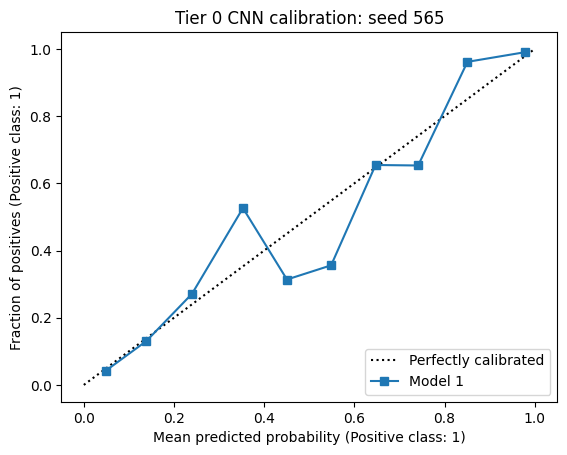

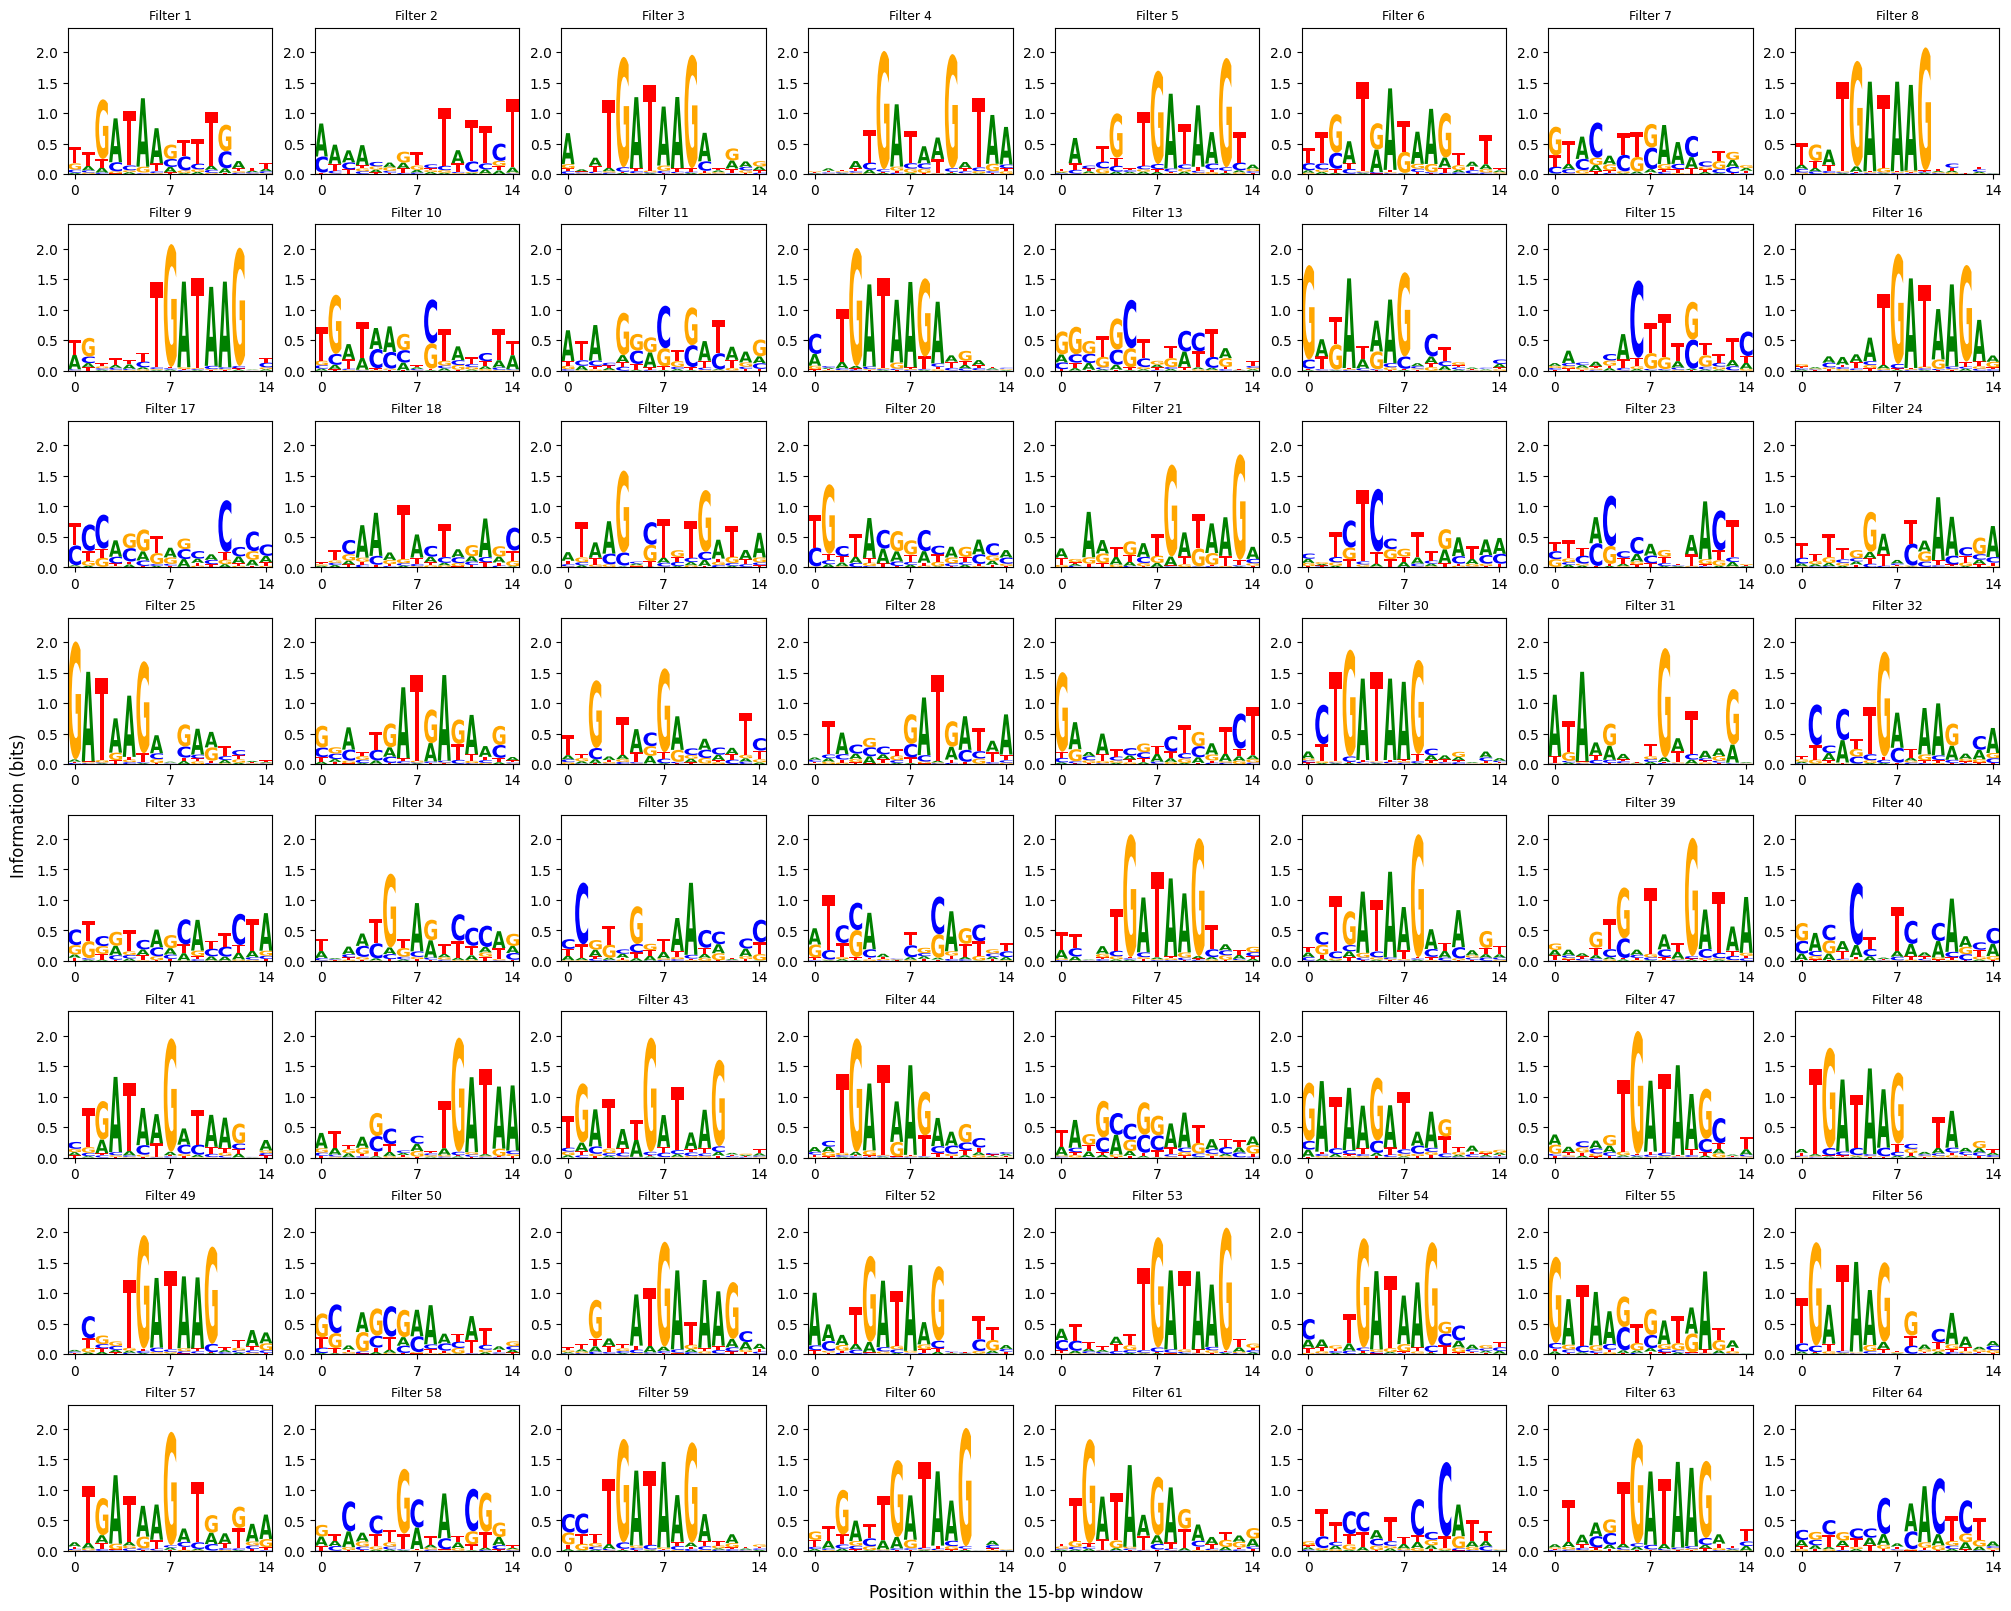

Saved; reload check passed.

Model 2: seed 566
PWM-scan AUROC: 0.9463
Epoch 1: val_loss=0.6417
Epoch 2: val_loss=0.3202
Epoch 3: val_loss=0.2877
Epoch 4: val_loss=0.2847
Epoch 5: val_loss=0.2859
Epoch 6: val_loss=0.2862
Epoch 7: val_loss=0.3050
Epoch 8: val_loss=0.3010
Epoch 9: val_loss=0.2812
Epoch 10: val_loss=0.2791
Test AUROC: 0.9454 | Test AP: 0.9552


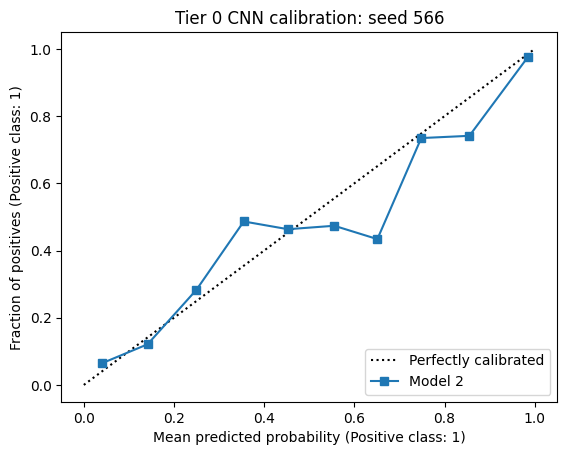

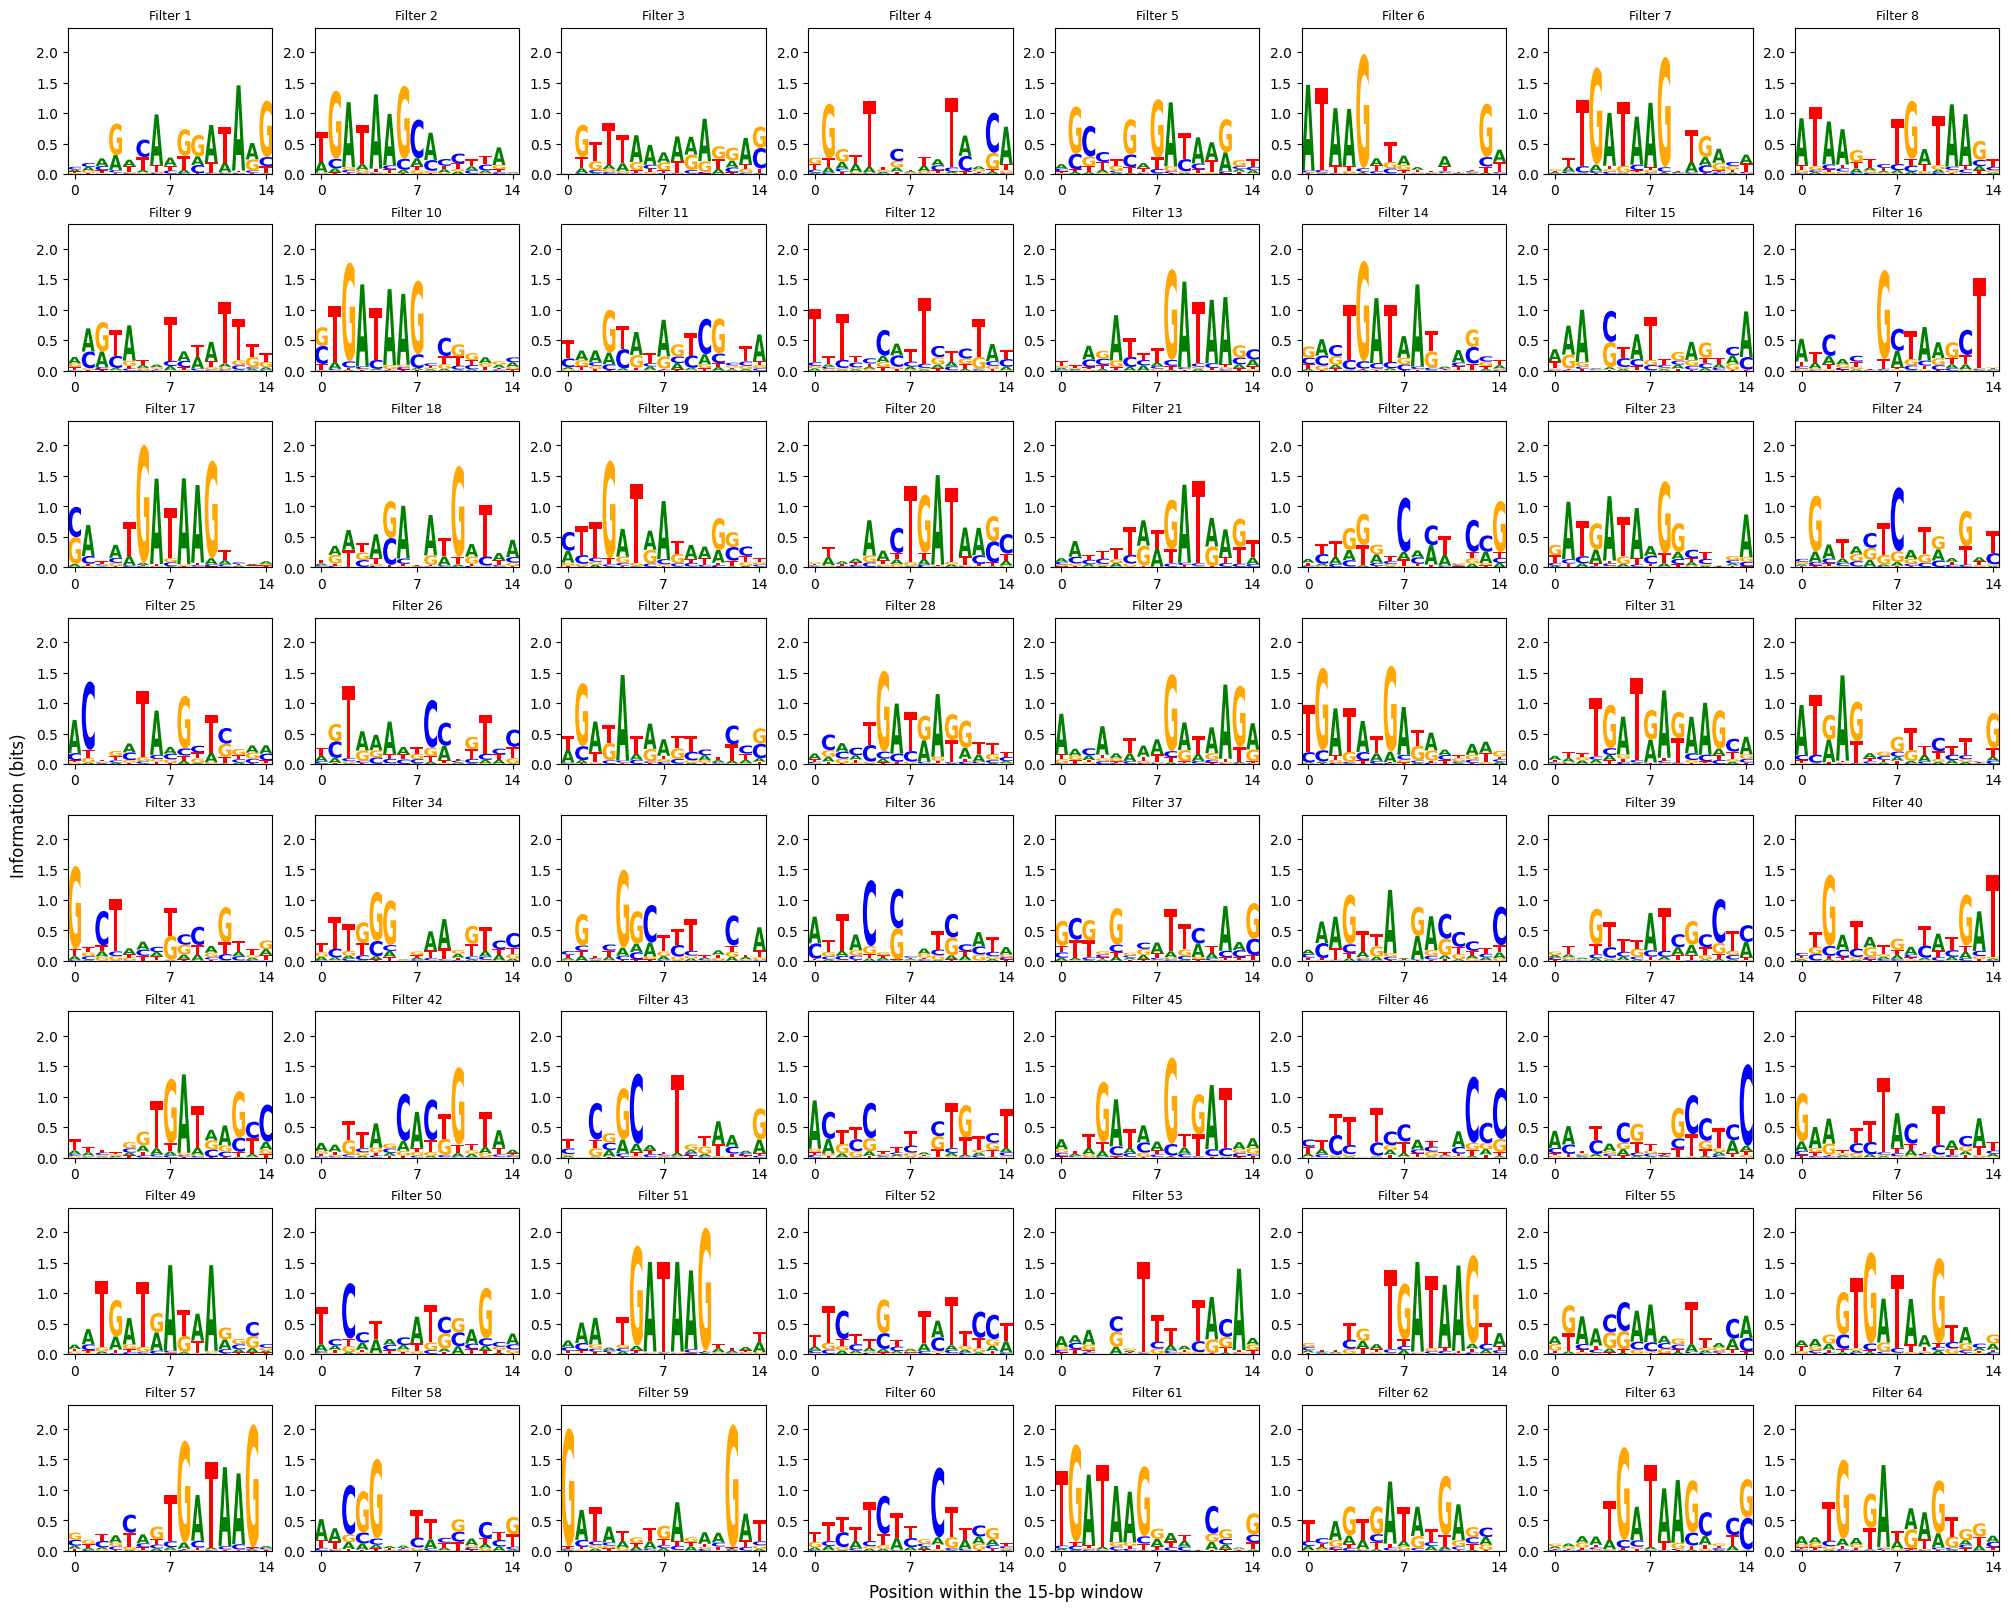

Saved; reload check passed.


In [6]:
# Run both seeds with the same architecture, split sizes, and training settings.
root = Path("tier0_results")
runs = {}
log_odds = np.log2(motif / background)
for number, seed in enumerate((565, 566), 1):
    print(f"\nModel {number}: seed {seed}")
    out = root / f"seed{seed}"
    out.mkdir(parents=True, exist_ok=True)
    X, y, mask = simulate(10000, seed)
    scores = np.zeros((len(X), 95))
    for j in range(7):
        scores += log_odds[j, X[:, j:j + 95]]
    pwm_auc = roc_auc_score(y, scores.max(axis=1))
    print(f"PWM-scan AUROC: {pwm_auc:.4f}")
    assert pwm_auc > 0.9
    train_loader = make_loader(X[:7000], y[:7000], shuffle=True, seed=seed)
    val_loader = make_loader(X[7000:8500], y[7000:8500])
    test_loader = make_loader(X[8500:], y[8500:])
    model = train_model(make_model(seed), train_loader, val_loader)

    # Evaluate the selected model on the untouched test split.
    model.eval()
    with torch.no_grad():
        p = torch.cat([model(x.to(device)).sigmoid().cpu() for x, _ in test_loader]).numpy().ravel()
    auc = roc_auc_score(y[8500:], p)
    ap = average_precision_score(y[8500:], p)
    print(f"Test AUROC: {auc:.4f} | Test AP: {ap:.4f}")
    pd.DataFrame([{"seed": seed, "PWM_AUROC": pwm_auc, "AUROC": auc, "AP": ap}]).to_csv(out / "metrics.csv", index=False)

    # Plot calibration and first-layer filter logos.
    CalibrationDisplay.from_predictions(y[8500:], p, n_bins=10, name=f"Model {number}")
    plt.title(f"Tier 0 CNN calibration: seed {seed}")
    plt.savefig(out / "calibration.png", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()
    plot_filters(model, val_loader, X[7000:8500], out / "filters.png")

    # Save everything needed to reload this model and its data for E2–E4.
    torch.save({"state_dict": {k: v.cpu() for k, v in model.state_dict().items()},
                "seed": seed, "padding": True, "architecture": str(model),
                "base_order": "ACGT", "output": "logits",
                "negative_protocol": "independent_background"}, out / "model.pt")
    np.savez_compressed(out / "data.npz", X_train=X[:7000], y_train=y[:7000],
                        X_val=X[7000:8500], y_val=y[7000:8500],
                        X_test=X[8500:], y_test=y[8500:], mask_test=mask[8500:],
                        p_test=p, motif=motif, background=background)

    # Reload the checkpoint and verify its predictions on one test batch.
    check = make_model(seed)
    check.load_state_dict(torch.load(out / "model.pt", map_location=device, weights_only=True)["state_dict"])
    check.eval()
    with torch.no_grad():
        restored = check(next(iter(test_loader))[0].to(device)).sigmoid().cpu().numpy().ravel()
    np.testing.assert_allclose(restored, p[:len(restored)], rtol=1e-5, atol=1e-6)
    print("Saved; reload check passed.")
    runs[seed] = (model, X, y, mask, p)

# Keep familiar variable names for later attribution work.
model, X, y, mask, p = runs[565]
model2, X2, y2, mask2, p2 = runs[566]
X_test, y_test, mask_test = X[8500:], y[8500:], mask[8500:]

## 7. Download results
Download `tier0_results.zip` after running this cell. Each seed folder contains `model.pt`, `data.npz`, `metrics.csv`, `calibration.png`, and `filters.png`.



In [7]:
# Record package versions and download both models and their results in one ZIP.
packages = ["torch", "numpy", "pandas", "scikit-learn", "matplotlib", "logomaker"]
(root / "versions.txt").write_text("\n".join(f"{name}=={version(name)}" for name in packages))
shutil.make_archive("tier0_results", "zip", root_dir=".", base_dir=str(root))
from google.colab import files
files.download("tier0_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>